# Die Vigenère-Chiffre

Die Caesar-Chiffre hat zwei grosse Schwächen, die wir beim Knacken
ausgenutzt haben:

1. Es gibt nur 25 mögliche Schlüssel. Ein Computer probiert sie in
   Bruchteilen einer Sekunde alle durch.
2. Jeder Buchstabe wird immer durch denselben Buchstaben ersetzt. Deshalb
   bleibt die Häufigkeitsverteilung der Buchstaben erhalten, und der
   häufigste Buchstabe im Geheimtext verrät meistens das `E`.

Die Vigenère-Chiffre behebt beide Schwächen mit einer einfachen Idee:
Statt alle Buchstaben um denselben Betrag zu verschieben, wird **jeder
Buchstabe um einen anderen Betrag** verschoben. Welcher Betrag das ist,
legt ein Schlüssel**wort** fest.

## Ein wenig Geschichte

Das Verfahren wurde 1553 vom italienischen Kryptologen Giovan Battista
Bellaso beschrieben. Seinen Namen verdankt es aber dem französischen
Diplomaten Blaise de Vigenère, der 1586 ein Buch über Verschlüsselung
veröffentlichte und dem die Erfindung später irrtümlich zugeschrieben
wurde.

Die Chiffre galt rund 300 Jahre lang als unknackbar und wurde in
Frankreich *le chiffre indéchiffrable* genannt, die nicht zu
entziffernde Chiffre. Erst um 1854 fand der Engländer Charles Babbage
einen Weg, sie zu brechen, veröffentlichte ihn aber nie. 1863 beschrieb
der preussische Offizier Friedrich Wilhelm Kasiski unabhängig davon ein
Verfahren, mit dem sich die Chiffre systematisch angreifen lässt.

## Die Idee: Ein Schlüsselwort statt einer Zahl

Bei der Caesar-Chiffre ist der Schlüssel eine Zahl, zum Beispiel 3. Bei
der Vigenère-Chiffre ist der Schlüssel ein Wort. In unserem Beispiel
verwenden wir das Schlüsselwort

<p style="text-align: center; font-size: 1.4em; letter-spacing: 0.3em;"><code>BUELRAIN</code></p>

Weil die Chiffre nur die Buchstaben `A` bis `Z` kennt, wird das `Ü` als
`UE` geschrieben.

Jeder Buchstabe des Schlüsselworts steht für eine Verschiebung. Dabei
gilt dieselbe Nummerierung wie bei der Caesar-Chiffre in Python:
`A` = 0, `B` = 1, `C` = 2 und so weiter bis `Z` = 25. Der Buchstabe gibt
also an, um wie viele Positionen verschoben wird:

| Schlüsselbuchstabe | `B` | `U` | `E` | `L` | `R` | `A` | `I` | `N` |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Verschiebung | 1 | 20 | 4 | 11 | 17 | 0 | 8 | 13 |

Unser Schlüsselwort besteht damit aus acht verschiedenen
Caesar-Verschiebungen. Der erste Buchstabe des Klartextes wird um 1
verschoben, der zweite um 20, der dritte um 4 und so weiter. Nach dem
achten Buchstaben ist das Schlüsselwort aufgebraucht, und es beginnt
wieder von vorne: Der neunte Buchstabe wird wieder um 1 verschoben, der
zehnte um 20 usw.

Man kann sich die Vigenère-Chiffre deshalb als **acht Caesar-Chiffren**
vorstellen, die sich reihum abwechseln.

## Verschlüsseln Schritt für Schritt

Wir verschlüsseln die Nachricht

<p style="text-align: center;"><code>ANGRIFF IM MORGENGRAUEN</code></p>

Wie bei der Caesar-Chiffre lassen wir Leerzeichen weg und schreiben nur
Grossbuchstaben. Leerzeichen würden einem Angreifer verraten, wo ein
Wort aufhört, und damit wertvolle Hinweise liefern.

**Schritt 1: Schlüsselwort unter den Klartext schreiben**

Das Schlüsselwort wird so oft wiederholt, bis es gleich lang ist wie der
Klartext:

```
Klartext:   ANGRIFFIMMORGENGRAUEN
Schlüssel:  BUELRAINBUELRAINBUELR
```

**Schritt 2: Jeden Buchstaben einzeln verschieben**

Nun wird jeder Klartextbuchstabe um den Wert des Schlüsselbuchstabens
darunter verschoben. Sehen wir uns die ersten drei Buchstaben genau an:

- `A` (0) mit Schlüssel `B` (1): 0 + 1 = 1, das ergibt `B`.
- `N` (13) mit Schlüssel `U` (20): 13 + 20 = 33. Das Alphabet hat nur 26
  Buchstaben, also beginnen wir wie bei der Caesar-Chiffre wieder vorne:
  33 − 26 = 7, das ergibt `H`.
- `G` (6) mit Schlüssel `E` (4): 6 + 4 = 10, das ergibt `K`.

Die folgende Tabelle zeigt die Rechnung für den ganzen Text:

| Nr. | Klartext | Schlüssel | Verschiebung | Rechnung | Geheimtext |
| ---: | :---: | :---: | ---: | :--- | :---: |
| 1 | `A` | `B` | 1 | 0 + 1 = 1 | `B` |
| 2 | `N` | `U` | 20 | 13 + 20 = 33 → 33 − 26 = 7 | `H` |
| 3 | `G` | `E` | 4 | 6 + 4 = 10 | `K` |
| 4 | `R` | `L` | 11 | 17 + 11 = 28 → 28 − 26 = 2 | `C` |
| 5 | `I` | `R` | 17 | 8 + 17 = 25 | `Z` |
| 6 | `F` | `A` | 0 | 5 + 0 = 5 | `F` |
| 7 | `F` | `I` | 8 | 5 + 8 = 13 | `N` |
| 8 | `I` | `N` | 13 | 8 + 13 = 21 | `V` |
| 9 | `M` | `B` | 1 | 12 + 1 = 13 | `N` |
| 10 | `M` | `U` | 20 | 12 + 20 = 32 → 32 − 26 = 6 | `G` |
| 11 | `O` | `E` | 4 | 14 + 4 = 18 | `S` |
| 12 | `R` | `L` | 11 | 17 + 11 = 28 → 28 − 26 = 2 | `C` |
| 13 | `G` | `R` | 17 | 6 + 17 = 23 | `X` |
| 14 | `E` | `A` | 0 | 4 + 0 = 4 | `E` |
| 15 | `N` | `I` | 8 | 13 + 8 = 21 | `V` |
| 16 | `G` | `N` | 13 | 6 + 13 = 19 | `T` |
| 17 | `R` | `B` | 1 | 17 + 1 = 18 | `S` |
| 18 | `A` | `U` | 20 | 0 + 20 = 20 | `U` |
| 19 | `U` | `E` | 4 | 20 + 4 = 24 | `Y` |
| 20 | `E` | `L` | 11 | 4 + 11 = 15 | `P` |
| 21 | `N` | `R` | 17 | 13 + 17 = 30 → 30 − 26 = 4 | `E` |

**Schritt 3: Geheimtext aufschreiben**

Der fertige Geheimtext lautet:

<p style="text-align: center;"><code>BHKCZFNVNGSCXEVTSUYPE</code></p>

Damit er trotzdem gut lesbar bleibt, wird der Geheimtext üblicherweise
in Fünfergruppen geschrieben. Die Gruppen haben nichts mit den Wörtern
des Klartextes zu tun:

<p style="text-align: center;"><code>BHKCZ FNVNG SCXEV TSUYP E</code></p>

## Das Vigenère-Quadrat

Ohne Computer ist das ständige Rechnen mühsam und fehleranfällig. Deshalb
benutzte man früher eine Tabelle, das sogenannte *Vigenère-Quadrat*
(lateinisch *tabula recta*). Jede Zeile enthält das Alphabet, aber jede
Zeile ist um eine Position weiter verschoben als die vorherige. Jede
Zeile ist also eine eigene Caesar-Chiffre.

@fig-vigenere-quadrat zeigt das vollständige Quadrat.

![Das Vigenère-Quadrat. Hervorgehoben ist die Verschlüsselung des
Klartextbuchstabens `N` mit dem Schlüsselbuchstaben `U`: Im Schnittpunkt
von Zeile `U` und Spalte `N` steht der Geheimtextbuchstabe
`H`.](vigenere_quadrat.svg){#fig-vigenere-quadrat}

So wird die Tabelle benutzt:

1. Die **Zeile** wird durch den Schlüsselbuchstaben bestimmt.
2. Die **Spalte** wird durch den Klartextbuchstaben bestimmt.
3. Im Schnittpunkt steht der Geheimtextbuchstabe.

Probieren wir es mit dem zweiten Buchstaben unseres Beispiels aus, dem
`N` mit dem Schlüsselbuchstaben `U`. In @fig-vigenere-quadrat ist dieser
Fall hervorgehoben: In der Zeile `U` und der Spalte `N` steht ein `H`.
Das stimmt mit der Rechnung oben überein.

Für unser Schlüsselwort `BUELRAIN` brauchen wir nur acht der 26 Zeilen.
Wer von Hand verschlüsselt, kann sich diese Zeilen herausschreiben:

| Schlüssel | **A** | **B** | **C** | **D** | **E** | **F** | **G** | **H** | **I** | **J** | **K** | **L** | **M** | **N** | **O** | **P** | **Q** | **R** | **S** | **T** | **U** | **V** | **W** | **X** | **Y** | **Z** |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **B** | B | C | D | E | F | G | H | I | J | K | L | M | N | O | P | Q | R | S | T | U | V | W | X | Y | Z | A |
| **U** | U | V | W | X | Y | Z | A | B | C | D | E | F | G | H | I | J | K | L | M | N | O | P | Q | R | S | T |
| **E** | E | F | G | H | I | J | K | L | M | N | O | P | Q | R | S | T | U | V | W | X | Y | Z | A | B | C | D |
| **L** | L | M | N | O | P | Q | R | S | T | U | V | W | X | Y | Z | A | B | C | D | E | F | G | H | I | J | K |
| **R** | R | S | T | U | V | W | X | Y | Z | A | B | C | D | E | F | G | H | I | J | K | L | M | N | O | P | Q |
| **A** | A | B | C | D | E | F | G | H | I | J | K | L | M | N | O | P | Q | R | S | T | U | V | W | X | Y | Z |
| **I** | I | J | K | L | M | N | O | P | Q | R | S | T | U | V | W | X | Y | Z | A | B | C | D | E | F | G | H |
| **N** | N | O | P | Q | R | S | T | U | V | W | X | Y | Z | A | B | C | D | E | F | G | H | I | J | K | L | M |

## Die Rechnung als Formel

Bei der Caesar-Chiffre haben wir die Verschlüsselung so geschrieben:

$$
x' = (x + n) \mod 26
$$

Bei der Vigenère-Chiffre hängt die Verschiebung $n$ von der Position im
Text ab. Ist $p_i$ der $i$-te Buchstabe des Klartextes, $k$ das
Schlüsselwort mit der Länge $m$ und $c_i$ der $i$-te Buchstabe des
Geheimtextes, dann gilt (die Positionen werden ab 0 gezählt):

$$
c_i = (p_i + k_{i \bmod m}) \mod 26
$$

Der Ausdruck $i \bmod m$ sorgt dafür, dass das Schlüsselwort immer wieder
von vorne beginnt. Bei unserem Schlüssel ist $m = 8$. Für den Buchstaben
an Position $i = 9$ wird also der Schlüsselbuchstabe an Position
$9 \bmod 8 = 1$ verwendet, das ist das `U`.

## Entschlüsseln

Zum Entschlüsseln wird die Verschiebung wieder rückgängig gemacht. Statt
zu addieren, wird der Wert des Schlüsselbuchstabens subtrahiert:

$$
p_i = (c_i - k_{i \bmod m}) \mod 26
$$

Für die ersten drei Buchstaben des Geheimtextes `BHK`:

- `B` (1) mit Schlüssel `B` (1): 1 − 1 = 0, das ergibt `A`.
- `H` (7) mit Schlüssel `U` (20): 7 − 20 = −13. Ist das Ergebnis
  negativ, zählen wir 26 dazu: −13 + 26 = 13, das ergibt `N`.
- `K` (10) mit Schlüssel `E` (4): 10 − 4 = 6, das ergibt `G`.

Im Vigenère-Quadrat sucht man dazu in der Zeile des
Schlüsselbuchstabens den Geheimtextbuchstaben. Die Spalte, in der er
steht, ist der Klartextbuchstabe.

Wichtig ist: Wer entschlüsseln will, muss **dasselbe Schlüsselwort**
kennen wie der Absender. Man spricht deshalb von einem *symmetrischen*
Verschlüsselungsverfahren.

## Warum die Häufigkeitsanalyse versagt

Vergleichen wir Klartext und Geheimtext genauer:

```
Klartext:   ANGRIFFIMMORGENGRAUEN
Schlüssel:  BUELRAINBUELRAINBUELR
Geheimtext: BHKCZFNVNGSCXEVTSUYPE
```

Dabei fallen einige Dinge auf:

- **Gleiche Klartextbuchstaben werden verschieden verschlüsselt.** Das
  `N` kommt dreimal vor und wird zu `H`, `V` und `E`. Das `G` wird zu
  `K`, `X` und `T`.
- **Gleiche Geheimtextbuchstaben stehen für verschiedene
  Klartextbuchstaben.** Das `V` im Geheimtext steht einmal für ein `I`
  und einmal für ein `N`.
- **Doppelbuchstaben verschwinden.** Aus `FF` in `ANGRIFF` wird `FN`, aus
  `MM` wird `NG`.

Genau darauf hat sich die Häufigkeitsanalyse verlassen. Bei der
Caesar-Chiffre konnten wir annehmen, dass der häufigste Buchstabe im
Geheimtext ein `E` ist. Bei der Vigenère-Chiffre wird das `E` je nach
Position zu einem von acht verschiedenen Buchstaben. Die typische
Häufigkeitsverteilung der deutschen Sprache wird dadurch verwischt, und
der häufigste Buchstabe im Geheimtext verrät nichts mehr.

### Ein Experiment: Häufigkeiten sichtbar machen

Ob die Verteilung tatsächlich verwischt wird, können wir mit einem
Experiment überprüfen. Dazu brauchen wir einen Text, der lang genug ist,
damit sich die typischen Häufigkeiten der deutschen Sprache zeigen. Wir
verwenden den Anfang des Johannesevangeliums (Johannes 1, 1–14) in der
Fassung der Zürcher Bibel von 1931. Die ersten vier Verse kennen wir
bereits aus der Lektion über die Caesar-Chiffre.

Das Experiment hat vier Schritte:

1. Den Klartext vorbereiten.
2. Den Klartext einmal mit der Caesar-Chiffre und einmal mit der
   Vigenère-Chiffre verschlüsseln.
3. In allen drei Texten die Buchstaben zählen.
4. Die Häufigkeiten in drei Histogrammen nebeneinanderstellen.

#### Schritt 1: Den Klartext vorbereiten

Wir speichern den Text in einer Variablen. Die drei Anführungszeichen
`"""` erlauben einen String über mehrere Zeilen.

In [1]:
text = """Im Anfang war das Wort, und das Wort war bei Gott, und von Gottes Wesen war das Wort.
Dieses war im Anfang bei Gott.
Alle Dinge sind durch das Wort geworden, und ohne dasselbe ist nicht eines geworden, das geworden ist.
In ihm war Leben, und das Leben war das Licht der Menschen.
Und das Licht scheint in der Finsternis, und die Finsternis hat es nicht begriffen.
Es trat ein Mensch auf, von Gott gesandt, sein Name war Johannes.
Dieser kam zum Zeugnis, um Zeugnis abzulegen von dem Licht, damit alle durch ihn glaubten.
Nicht er war das Licht, sondern er sollte Zeugnis ablegen von dem Licht.
Das wahre Licht, das jeden Menschen erleuchtet, war im Kommen in die Welt.
Es war in der Welt, und die Welt ist durch dasselbe geworden, und die Welt hat es nicht erkannt.
Es kam in sein Eigentum, und die Seinen nahmen es nicht auf.
Allen denen aber, die es aufnahmen, gab es Macht, Kinder Gottes zu werden, denen, die an seinen Namen glauben;
die nicht aus dem Blut, noch aus dem Willen des Fleisches, noch aus dem Willen des Mannes, sondern aus Gott geboren sind.
Und das Wort wurde Fleisch und wohnte unter uns, und wir schauten seine Herrlichkeit, eine Herrlichkeit als des Eingeborenen vom Vater, voller Gnade und Wahrheit."""

Wie in der Lektion über die Caesar-Chiffre arbeiten wir nur mit den
Grossbuchstaben von `A` bis `Z`. Die Funktion `clean` wandelt den Text in
Grossbuchstaben um und behält nur die Buchstaben. Leerzeichen,
Satzzeichen und Zeilenumbrüche fallen weg.

In [2]:
def clean(text: str) -> str:
    result = ""

    for char in text.upper():
        if 'A' <= char <= 'Z':
            result += char

    return result


plain = clean(text)
print(len(plain), "Buchstaben")

965 Buchstaben


#### Schritt 2: Verschlüsseln

Die Funktion `caesar` kennen wir bereits. Weil der Text nur noch
Buchstaben enthält, genügt hier die einfache Version.

Die Funktion `vigenere` funktioniert fast gleich. Der Unterschied: Die
Verschiebung ist nicht für alle Buchstaben gleich, sondern wird für jeden
Buchstaben aus dem Schlüsselwort berechnet. Dafür brauchen wir die
Position `i` des Buchstabens im Text. Die Funktion `enumerate` liefert
in der `for`-Schleife zu jedem Zeichen auch seine Position. Mit
`i % len(key)` beginnt das Schlüsselwort nach dem letzten Buchstaben
wieder von vorne, genau wie in der Formel
$c_i = (p_i + k_{i \bmod m}) \mod 26$.

In [3]:
def caesar(text: str, shift: int) -> str:
    result = ""

    for char in text:
        shifted = (ord(char) - ord('A') + shift) % 26 + ord('A')
        result += chr(shifted)

    return result


def vigenere(text: str, key: str) -> str:
    result = ""

    for i, char in enumerate(text):
        shift = ord(key[i % len(key)]) - ord('A')
        shifted = (ord(char) - ord('A') + shift) % 26 + ord('A')
        result += chr(shifted)

    return result

Wir verschlüsseln den Klartext mit der Caesar-Chiffre und dem Schlüssel
3 sowie mit der Vigenère-Chiffre und dem Schlüssel `BUELRAIN`.

In [4]:
caesar_text = caesar(plain, 3)
vigenere_text = vigenere(plain, "BUELRAIN")

Damit die Texte lesbar bleiben, geben wir sie in Fünfergruppen aus, zehn
Gruppen pro Zeile. Die Funktion `print_groups` schneidet dazu den Text
mit `text[start:start + 5]` in Stücke von fünf Buchstaben.

In [5]:
def print_groups(text: str, size=5, per_line=10) -> None:
    groups = []
    for start in range(0, len(text), size):
        groups.append(text[start:start + size])

    for start in range(0, len(groups), per_line):
        print(" ".join(groups[start:start + per_line]))

In [6]:
print("Klartext")
print_groups(plain)

Klartext
IMANF ANGWA RDASW ORTUN DDASW ORTWA RBEIG OTTUN DVONG OTTES
WESEN WARDA SWORT DIESE SWARI MANFA NGBEI GOTTA LLEDI NGESI
NDDUR CHDAS WORTG EWORD ENUND OHNED ASSEL BEIST NICHT EINES
GEWOR DENDA SGEWO RDENI STINI HMWAR LEBEN UNDDA SLEBE NWARD
ASLIC HTDER MENSC HENUN DDASL ICHTS CHEIN TINDE RFINS TERNI
SUNDD IEFIN STERN ISHAT ESNIC HTBEG RIFFE NESTR ATEIN MENSC
HAUFV ONGOT TGESA NDTSE INNAM EWARJ OHANN ESDIE SERKA MZUMZ
EUGNI SUMZE UGNIS ABZUL EGENV ONDEM LICHT DAMIT ALLED URCHI
HNGLA UBTEN NICHT ERWAR DASLI CHTSO NDERN ERSOL LTEZE UGNIS
ABLEG ENVON DEMLI CHTDA SWAHR ELICH TDASJ EDENM ENSCH ENERL
EUCHT ETWAR IMKOM MENIN DIEWE LTESW ARIND ERWEL TUNDD IEWEL
TISTD URCHD ASSEL BEGEW ORDEN UNDDI EWELT HATES NICHT ERKAN
NTESK AMINS EINEI GENTU MUNDD IESEI NENNA HMENE SNICH TAUFA
LLEND ENENA BERDI EESAU FNAHM ENGAB ESMAC HTKIN DERGO TTESZ
UWERD ENDEN ENDIE ANSEI NENNA MENGL AUBEN DIENI CHTAU SDEMB
LUTNO CHAUS DEMWI LLEND ESFLE ISCHE SNOCH AUSDE MWILL ENDES
MANNE SSOND ERNAU SGOTT GEBOR E

In [7]:
print("Caesar-Chiffre (Schlüssel 3)")
print_groups(caesar_text)

Caesar-Chiffre (Schlüssel 3)
LPDQI DQJZD UGDVZ RUWXQ GGDVZ RUWZD UEHLJ RWWXQ GYRQJ RWWHV
ZHVHQ ZDUGD VZRUW GLHVH VZDUL PDQID QJEHL JRWWD OOHGL QJHVL
QGGXU FKGDV ZRUWJ HZRUG HQXQG RKQHG DVVHO EHLVW QLFKW HLQHV
JHZRU GHQGD VJHZR UGHQL VWLQL KPZDU OHEHQ XQGGD VOHEH QZDUG
DVOLF KWGHU PHQVF KHQXQ GGDVO LFKWV FKHLQ WLQGH UILQV WHUQL
VXQGG LHILQ VWHUQ LVKDW HVQLF KWEHJ ULIIH QHVWU DWHLQ PHQVF
KDXIY RQJRW WJHVD QGWVH LQQDP HZDUM RKDQQ HVGLH VHUND PCXPC
HXJQL VXPCH XJQLV DECXO HJHQY RQGHP OLFKW GDPLW DOOHG XUFKL
KQJOD XEWHQ QLFKW HUZDU GDVOL FKWVR QGHUQ HUVRO OWHCH XJQLV
DEOHJ HQYRQ GHPOL FKWGD VZDKU HOLFK WGDVM HGHQP HQVFK HQHUO
HXFKW HWZDU LPNRP PHQLQ GLHZH OWHVZ DULQG HUZHO WXQGG LHZHO
WLVWG XUFKG DVVHO EHJHZ RUGHQ XQGGL HZHOW KDWHV QLFKW HUNDQ
QWHVN DPLQV HLQHL JHQWX PXQGG LHVHL QHQQD KPHQH VQLFK WDXID
OOHQG HQHQD EHUGL HHVDX IQDKP HQJDE HVPDF KWNLQ GHUJR WWHVC
XZHUG HQGHQ HQGLH DQVHL QHQQD PHQJO DXEHQ GLHQL FKWDX VGHPE
OXWQR FKDXV GHPZL OOHQG HVIOH LVFKH VQRFK DXVGH PZLOO HQGHV
PDQQH VVRQG

In [8]:
print("Vigenère-Chiffre (Schlüssel BUELRAIN)")
print_groups(vigenere_text)

Vigenère-Chiffre (Schlüssel BUELRAIN)
JGEYW AVTXU VORSE BSNYY UDIFX IVENA ZOFCK ZKTCA EPSYX OBGFM
APJEV JBLHL JWWEU XMPJE AJBLM XRNNN OAFPZ GWGUU PWVDQ AHYWT
EDLHS WLORS EBSNK PNOZQ FHYYU OPAFX EDJET OFCWE EIKUU YMYVS
ORXIV OVNLN TAIHF RLROC WEZNQ UNQEC CEJRO OROUA AYFVI YNAZQ
BMPTT HBQFL QPESK UFHYY UDIFM CGSKS KUFCR EZNLR SZMYJ TMEOC
WFEDL VFZMY JTMEO CWSRT MFOCG SKBMT SCJQV NMFUL EEVIV ZFHWN
YACSW IRRFT BTFME YUTAR JHRLD EENSD SSRNV RTXMP JEZXB GDFDZ
MHHHM DLMHR VARTJ AJMVF IRVND BOXIX CIKUU XEXZT IYMYH FICPV
IHKWR UJGFH RTTHB RSQEC UAAYJ WLEJO VQFLR PISWY MNIKV UOAJM
EMCEO ROPSY UEUYJ WLEUA AJBBV PCIKU UXEDA ELROG IYJCP ROYVW
VUKUU YXHRR QZLIQ XVNQA ECIHV LBRTQ ECZNL RSQIW KUVQE CIHVL
BVTNH FICPQ BMWPC BMTFQ SCUEV HOXHT VWMYU BEEVS VVDBX PIKIA
ONIDB AUVOM ITEEQ TFHXF DUVQE CIDVI VROHE SDEVR THMNY TIHGU
PWVNL ROYRL SEZQJ YIDRU NABBQ PEGIO FMQLT HBXJH HPIGW GUYWK
LWMEE YROVN MAECI LESMV OYRYR MMAHF EFSEV QJYRT THBNV MHPDB
THUHS NYACF EYQHZ LTROX IDWLM VTWLP JNWPI UYDUE UJJFP PEDMF
NU

Schon von blossem Auge fällt etwas auf: Der Klartext beginnt mit
`IMANF ANGWA RDASW ORT…`, die Caesar-Chiffre entsprechend mit
`LPDQI DQJZD UGDVZ RUW…`. Bei der Caesar-Chiffre wird jedes `A` zu `D`,
die Muster des Klartextes bleiben also erhalten. Bei der Vigenère-Chiffre
sind sie verschwunden.

#### Schritt 3: Buchstaben zählen

Die Funktion `letter_frequency` kennen wir aus der Lektion über das
Knacken der Caesar-Chiffre. Sie gibt für jeden Buchstaben von `A` bis `Z`
an, wie viel Prozent des Textes er ausmacht.

In [9]:
def letter_frequency(text: str) -> dict[str, float]:
    counts = {}
    for code in range(ord('A'), ord('Z') + 1):
        counts[chr(code)] = 0

    for char in text:
        counts[char] += 1

    frequency = {}
    for letter, count in counts.items():
        frequency[letter] = count / len(text) * 100

    return frequency

In [10]:
plain_frequency = letter_frequency(plain)
caesar_frequency = letter_frequency(caesar_text)
vigenere_frequency = letter_frequency(vigenere_text)

#### Schritt 4: Die Histogramme zeichnen

Für die Darstellung verwenden wir die Bibliothek
[matplotlib](https://matplotlib.org/). Sie ist die bekannteste
Python-Bibliothek zum Zeichnen von Diagrammen. Üblicherweise wird ihr
Teil `pyplot` unter dem kurzen Namen `plt` importiert.

In [11]:
import matplotlib.pyplot as plt

Beginnen wir mit einem einzelnen Histogramm für den Klartext. Ein
Histogramm zeigt für jeden Buchstaben einen Balken, dessen Höhe der
Häufigkeit entspricht. In matplotlib zeichnet die Funktion `bar` solche
Balken. Sie braucht zwei Listen gleicher Länge:

- die Beschriftungen der Balken, hier die Buchstaben (`letters`),
- die Höhen der Balken, hier die Häufigkeiten in Prozent (`values`).

Ein Dictionary liefert uns beides: `keys()` gibt die Buchstaben,
`values()` die Häufigkeiten. Mit `list(...)` machen wir daraus Listen.

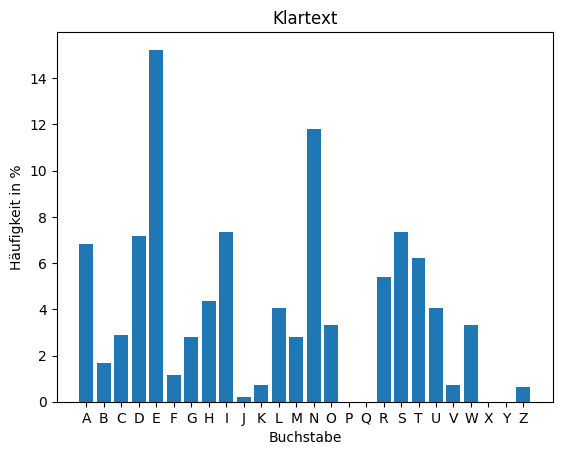

In [12]:
letters = list(plain_frequency.keys())
values = list(plain_frequency.values())

plt.bar(letters, values)
plt.title("Klartext")
plt.xlabel("Buchstabe")
plt.ylabel("Häufigkeit in %")
plt.show()

Die einzelnen Zeilen bewirken Folgendes:

- `plt.bar(letters, values)` zeichnet die Balken.
- `plt.title`, `plt.xlabel` und `plt.ylabel` beschriften das Diagramm und
  die beiden Achsen.
- `plt.show()` zeigt das fertige Diagramm an.

Man erkennt deutlich das typische Bild der deutschen Sprache: Das `E`
ragt heraus, gefolgt von `N`, und Buchstaben wie `Q`, `X` und `Y` kommen
gar nicht vor.

Für den Vergleich wollen wir die drei Histogramme untereinander
anordnen. Dafür erstellt `plt.subplots(3, 1)` eine Abbildung (`fig`) mit
drei Diagrammen in drei Zeilen und einer Spalte. Die drei Diagramme
erhalten wir in der Liste `axes`. Zwei Einstellungen helfen beim
Vergleichen:

- `sharey=True` sorgt dafür, dass alle drei Diagramme dieselbe Skala auf
  der y-Achse haben. Nur so lassen sich die Höhen der Balken direkt
  vergleichen.
- `figsize=(8, 9)` legt die Grösse der Abbildung in Zoll fest (Breite,
  Höhe).

Weil wir dreimal fast dasselbe zeichnen, schreiben wir dafür eine
Funktion `plot_frequency`. Sie erhält das Diagramm `ax`, in das
gezeichnet werden soll, die Häufigkeiten und einen Titel. Bei einem
einzelnen Diagramm heissen die Methoden für die Beschriftung
`set_title`, `set_xlabel` und `set_ylabel` statt `title`, `xlabel` und
`ylabel`.

Zusätzlich zeichnet `ax.axhline` eine waagrechte gestrichelte Linie auf
der Höhe $100 / 26 \approx 3.85$ %. So häufig wäre jeder Buchstabe, wenn
alle Buchstaben gleich oft vorkämen. Je näher die Balken an dieser Linie
liegen, desto flacher ist die Verteilung.

In [13]:
def plot_frequency(ax, frequency: dict[str, float], title: str) -> None:
    letters = list(frequency.keys())
    values = list(frequency.values())

    ax.bar(letters, values)
    ax.axhline(100 / 26, color="gray", linestyle="--", label="Gleichverteilung")
    ax.set_title(title)
    ax.set_ylabel("Häufigkeit in %")
    ax.legend()

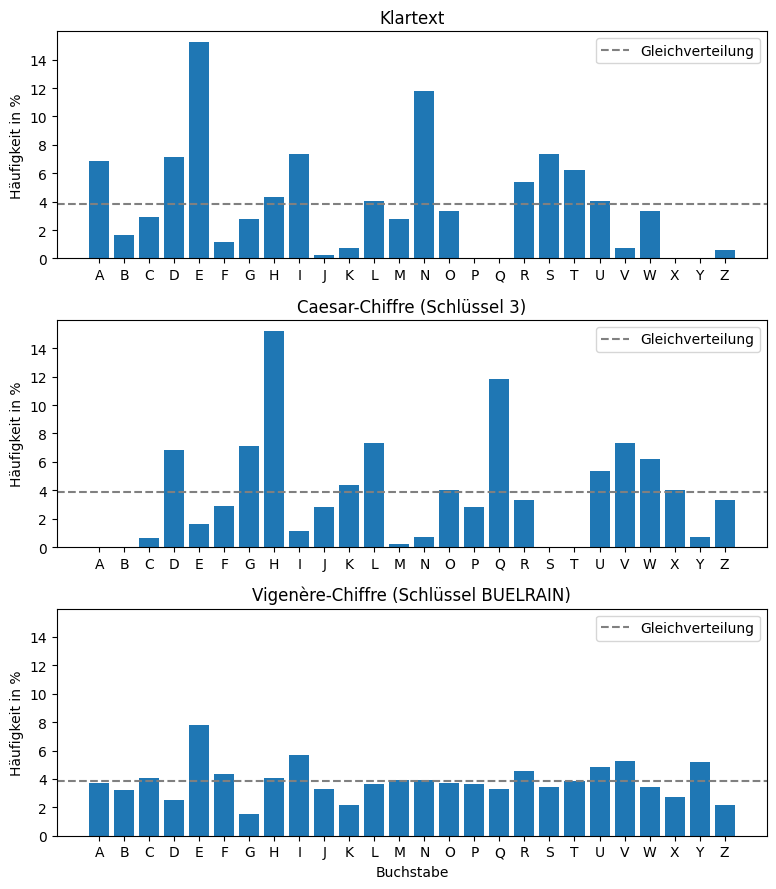

In [14]:
#| label: fig-histogramme
#| fig-cap: "Buchstabenhäufigkeiten im Klartext, in der Caesar-Chiffre und in der Vigenère-Chiffre."

fig, axes = plt.subplots(3, 1, sharey=True, figsize=(8, 9))

plot_frequency(axes[0], plain_frequency, "Klartext")
plot_frequency(axes[1], caesar_frequency, "Caesar-Chiffre (Schlüssel 3)")
plot_frequency(axes[2], vigenere_frequency, "Vigenère-Chiffre (Schlüssel BUELRAIN)")

axes[2].set_xlabel("Buchstabe")
fig.tight_layout()
plt.show()

`fig.tight_layout()` ordnet die drei Diagramme so an, dass sich Titel
und Beschriftungen nicht überlappen.

#### Auswertung

@fig-histogramme zeigt das Ergebnis des Experiments:

- **Caesar-Chiffre:** Das Histogramm sieht genau gleich aus wie beim
  Klartext, es ist nur um drei Buchstaben nach rechts verschoben. Der
  höchste Balken steht nun beim `H` statt beim `E`, und auch die Lücken
  wandern mit: Statt `P`, `Q`, `X` und `Y` fehlen nun `S`, `T`, `A` und
  `B`. Genau das nutzt die
  Häufigkeitsanalyse aus: Wer den höchsten Balken findet, kennt den
  Schlüssel.
- **Vigenère-Chiffre:** Die Verteilung ist deutlich flacher. Es gibt
  keinen Balken mehr, der so klar heraussticht wie das `E` im Klartext,
  und die meisten Balken liegen nahe bei der gestrichelten Linie. Auch
  `P`, `Q`, `X` und `Y`, die im Klartext gar nicht vorkommen, tauchen
  nun auf. Es gibt keine Lücken mehr.

Dass die Verteilung flacher wird, lässt sich auch in Zahlen ausdrücken.
Die Funktion `max` mit dem Argument `key=frequency.get` liefert den
Buchstaben mit der grössten Häufigkeit.

In [15]:
for name, frequency in [("Klartext", plain_frequency),
                        ("Caesar", caesar_frequency),
                        ("Vigenère", vigenere_frequency)]:
    most_common = max(frequency, key=frequency.get)
    print(f"{name:10} häufigster Buchstabe: {most_common} ({frequency[most_common]:.1f} %)")

Klartext   häufigster Buchstabe: E (15.2 %)
Caesar     häufigster Buchstabe: H (15.2 %)
Vigenère   häufigster Buchstabe: E (7.8 %)


Bei der Caesar-Chiffre ist der höchste Balken genau gleich hoch wie im
Klartext. Bei der Vigenère-Chiffre ist er nur noch etwa halb so hoch.

Auffällig ist, dass auch bei der Vigenère-Chiffre das `E` der häufigste
Buchstabe ist. Ist die Häufigkeitsanalyse also doch erfolgreich? Prüfen
wir das nach. Zuerst schauen wir, zu welchen Buchstaben das `E` des
Klartextes verschlüsselt wurde. Dazu gehen wir mit `enumerate` durch den
Klartext und merken uns bei jedem `E` den Buchstaben, der an derselben
Position im Geheimtext steht.

In [16]:
encrypted_e = []

for i, char in enumerate(plain):
    if char == "E" and vigenere_text[i] not in encrypted_e:
        encrypted_e.append(vigenere_text[i])

print(sorted(encrypted_e))

['E', 'F', 'I', 'M', 'P', 'R', 'V', 'Y']


Das `E` des Klartextes ist zu acht verschiedenen Buchstaben geworden,
einem für jeden Buchstaben des Schlüssels. Nur dort, wo im Schlüssel das
`A` steht, ist es ein `E` geblieben.

Umgekehrt können wir zählen, aus welchen Klartextbuchstaben die `E` im
Geheimtext entstanden sind.

In [17]:
origin_of_e = {}

for i, char in enumerate(vigenere_text):
    if char == "E":
        letter = plain[i]
        origin_of_e[letter] = origin_of_e.get(letter, 0) + 1

print(origin_of_e)

{'A': 13, 'W': 3, 'T': 9, 'D': 10, 'E': 22, 'R': 5, 'N': 11, 'K': 2}


Von den 75 `E` im Geheimtext waren nur 22 schon im Klartext ein `E`,
also weniger als ein Drittel. Die übrigen stammen von `A`, `N`, `D`, `T`
und weiteren Buchstaben. Bei der Vigenère-Chiffre ist jeder Buchstabe im
Geheimtext eine Mischung aus acht verschiedenen Klartextbuchstaben. Beim
`E` im Geheimtext sind das zufällig `E`, `A`, `N`, `D`, `T` und `R`, also
besonders häufige Buchstaben, sowie `W` und `K`. Deshalb ist sein Balken
etwas höher als die anderen. Dass das `E` selbst darunter ist, liegt am
`A` im Schlüssel, einer Schwäche, die wir weiter unten noch genauer
betrachten.

Wer annimmt, dass jedes `E` im Geheimtext auch im Klartext ein `E` ist,
liegt also in mehr als zwei von drei Fällen falsch. Die
Häufigkeitsanalyse, wie wir sie bei der Caesar-Chiffre verwendet haben,
funktioniert hier nicht mehr.

### Ein grösserer Schlüsselraum

Auch Brute Force wird schwieriger. Ein Schlüsselwort mit acht Buchstaben
erlaubt

$$
26^8 = 208\,827\,064\,576
$$

also rund 209 Milliarden verschiedene Schlüssel. Ein Computer, der eine
Million Schlüssel pro Sekunde ausprobiert, wäre damit rund 58 Stunden
beschäftigt. Für die Menschen des 16. Jahrhunderts war das völlig
undenkbar. Und auch ein heutiger Computer ist nicht mehr in
Sekundenbruchteilen fertig wie bei der Caesar-Chiffre.

## Die Schwächen der Vigenère-Chiffre

Ganz so sicher, wie man 300 Jahre lang glaubte, ist die Chiffre aber
nicht.

**Der Buchstabe `A` im Schlüssel.** Da `A` für eine Verschiebung um 0
steht, bleibt jeder Buchstabe an dieser Position unverändert. In unserem
Beispiel steht das `A` an der sechsten Stelle des Schlüssels, und
tatsächlich bleiben das `F` (Position 6) und das `E` (Position 14) im
Geheimtext stehen. Ein `A` im Schlüssel ist also ein kleines Leck.

**Die Wiederholung des Schlüssels.** Die eigentliche Schwäche liegt
darin, dass sich das Schlüsselwort wiederholt. Alle Buchstaben an den
Positionen 1, 9, 17, ... werden mit derselben Verschiebung (`B`)
verschlüsselt, alle an den Positionen 2, 10, 18, ... mit derselben
Verschiebung (`U`) und so weiter. Kennt ein Angreifer die Länge des
Schlüssels, kann er den Geheimtext in acht Gruppen aufteilen. Jede
Gruppe ist eine gewöhnliche Caesar-Chiffre und lässt sich mit der
Häufigkeitsanalyse aus der letzten Lektion knacken. Damit das klappt,
muss der Geheimtext allerdings lang genug sein, denn jede Gruppe
enthält nur jeden achten Buchstaben.

**Die Schlüssellänge finden.** Bleibt die Frage, wie man die Länge des
Schlüssels herausfindet. Hier setzt das Verfahren von Kasiski an: Kommt
in einem langen Text dieselbe Buchstabenfolge (zum Beispiel `DER` oder
`UND`) mehrmals vor und trifft sie zufällig auf dieselbe Stelle im
Schlüssel, entsteht im Geheimtext zweimal dieselbe Buchstabenfolge. Der
Abstand zwischen solchen Wiederholungen ist dann ein Vielfaches der
Schlüssellänge. Findet man mehrere solche Wiederholungen, verrät ihr
gemeinsamer Teiler die Länge des Schlüssels.

Daraus folgt: Je länger der Schlüssel im Vergleich zum Text, desto
sicherer ist die Chiffre. Ist der Schlüssel zufällig, gleich lang wie
der Text und wird er nur ein einziges Mal verwendet, ist die
Verschlüsselung sogar beweisbar unknackbar. Dieses Verfahren heisst
*One-Time-Pad*.

::: {.callout-note icon=false}
## Aufgaben

1. Verschlüsseln Sie Ihren Vornamen mit dem Schlüssel `BUELRAIN`. Benutzen
   Sie dazu das Vigenère-Quadrat.
2. Entschlüsseln Sie die folgende Nachricht, die ebenfalls mit dem
   Schlüssel `BUELRAIN` verschlüsselt wurde:

   <p style="text-align: center;"><code>WCKPE EZRJM XYZCP GVHOY RCSOB L</code></p>

3. Verschlüsseln Sie den Text `AAAAAAAAAAAAAAAA` (16-mal `A`) mit dem
   Schlüssel `BUELRAIN`. Was fällt Ihnen auf? Was bedeutet das für die
   Sicherheit, wenn ein Angreifer einen Teil des Klartextes kennt?
4. Weshalb ist `AAAA` ein schlechter Schlüssel? Welcher Chiffre entspricht
   ein Schlüssel wie `DDDD`?
:::